In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.linear_model import LinearRegression , Lasso ,Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.experimental import enable_hist_gradient_boosting  # Needed for HistGB
from sklearn.ensemble import (RandomForestRegressor,ExtraTreesRegressor,BaggingRegressor,
                              AdaBoostRegressor ,GradientBoostingRegressor,HistGradientBoostingRegressor
                              , VotingRegressor,StackingRegressor)
#import xgboost as xgb
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
#import lightgbm as lgb
from lightgbm import LGBMRegressor

c:\Users\donia\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\experimental\enable_hist_gradient_boosting.py:18: UserWarning: Since version 1.0, it is not needed to import enable_hist_gradient_boosting anymore. HistGradientBoostingClassifier and HistGradientBoostingRegressor are now stable and can be normally imported from sklearn.ensemble.
  warnings.warn(


**Data Cleaning**

In [2]:
df = pd.read_csv(r"D:\Material of Machine Learning Course\08_P1- Linear Regression & Metrics\Project Student Performance\Student_Performance.csv")

In [3]:
df.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1.0,91
1,4,82,No,4,2.0,65
2,8,51,Yes,7,2.0,45
3,5,52,Yes,5,2.0,36
4,7,75,No,8,5.0,66


In [4]:
df.shape

(10000, 6)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Hours Studied                     10000 non-null  int64  
 1   Previous Scores                   10000 non-null  int64  
 2   Extracurricular Activities        8428 non-null   str    
 3   Sleep Hours                       10000 non-null  int64  
 4   Sample Question Papers Practiced  7144 non-null   float64
 5   Performance Index                 10000 non-null  int64  
dtypes: float64(1), int64(4), str(1)
memory usage: 468.9 KB


In [6]:
df.isnull().sum()

Hours Studied                          0
Previous Scores                        0
Extracurricular Activities          1572
Sleep Hours                            0
Sample Question Papers Practiced    2856
Performance Index                      0
dtype: int64

In [7]:
df['Extracurricular Activities'] = df['Extracurricular Activities'].fillna(
    df['Extracurricular Activities'].mode()[0]
)

df['Sample Question Papers Practiced'] = df['Sample Question Papers Practiced'].fillna(
    df['Sample Question Papers Practiced'].median()
)

In [8]:
print(df.isnull().sum())

Hours Studied                       0
Previous Scores                     0
Extracurricular Activities          0
Sleep Hours                         0
Sample Question Papers Practiced    0
Performance Index                   0
dtype: int64


In [9]:
df.duplicated().sum()

np.int64(192)

In [10]:
df.drop_duplicates(inplace=True)

<Axes: xlabel='Extracurricular Activities', ylabel='count'>

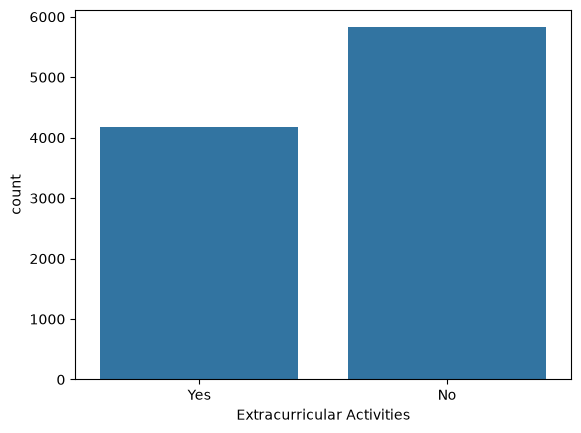

In [10]:
sns.countplot(data=df, x='Extracurricular Activities')

<Axes: xlabel='Hours Studied', ylabel='Performance Index'>

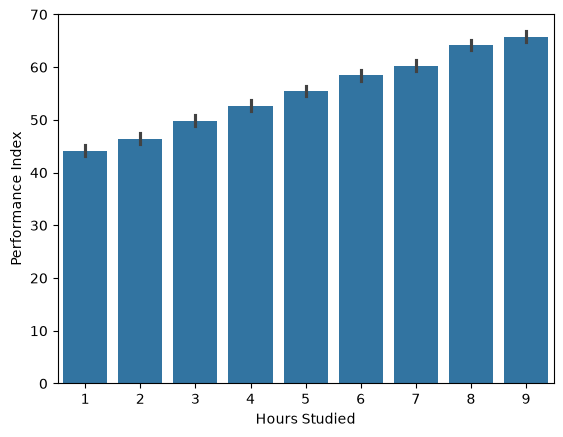

In [11]:
sns.barplot(data=df, x='Hours Studied', y='Performance Index')

<Axes: xlabel='Previous Scores', ylabel='Performance Index'>

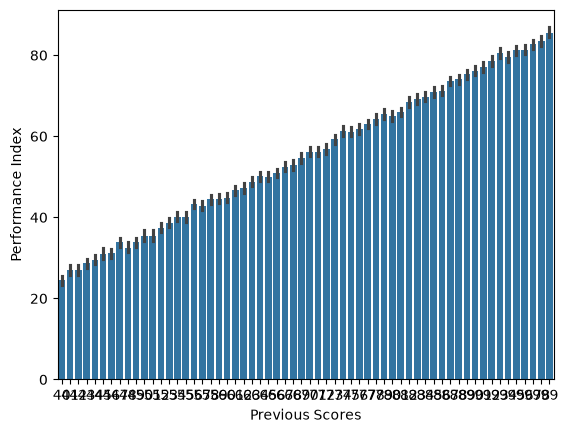

In [12]:
sns.barplot(data=df, x='Previous Scores', y='Performance Index')

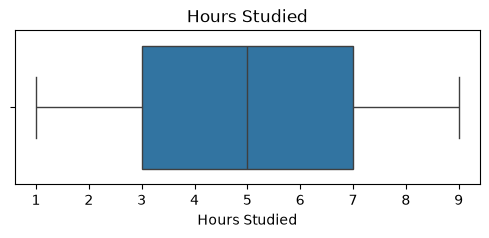

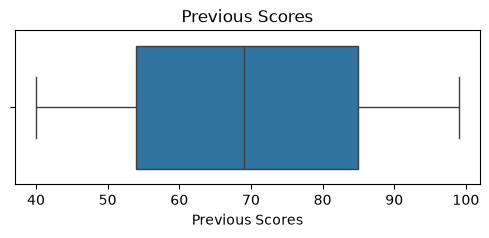

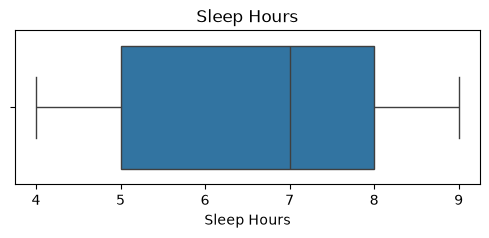

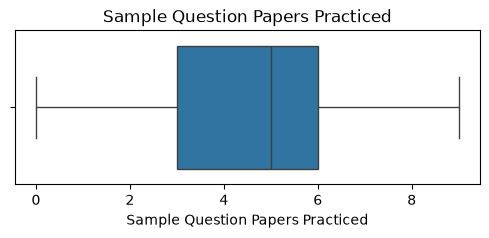

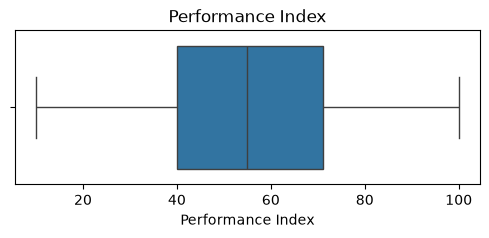

In [13]:
for col in df.select_dtypes(include='number').columns:
    plt.figure(figsize=(6, 2))
    sns.boxplot(x=df[col])
    plt.title(col)
    plt.show()

In [14]:
df['Extracurricular Activities'] = df['Extracurricular Activities'].map({
    'Yes': 1,
    'No': 0
})

In [15]:
from sklearn.model_selection import train_test_split
x = df.drop('Performance Index', axis=1)
y = df['Performance Index']

X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [16]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(X_train)
x_test_scaled = scaler.transform(X_test)

In [21]:
models ={
    "Linear Regression":LinearRegression(),
    "Lasso":Lasso(),
    "Ridge":Ridge(),
    "KNN":KNeighborsRegressor(n_neighbors=5,metric='minkowski',p=1), #  minkowski , euclidean , manhattan
    "SVM":SVR(kernel='linear', C=100, gamma=1), # kernel='rbf' / kernel='poly', degree=4 / kernel='sigmoid
    "Decision Tree":DecisionTreeRegressor(criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "Random Forest":RandomForestRegressor(n_estimators=50,criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "ExtraTrees": ExtraTreesRegressor(n_estimators=100, random_state=42),
    "Bagging": BaggingRegressor(estimator=DecisionTreeRegressor(criterion='squared_error',max_depth=10),n_estimators=50, random_state=42),
    "AdaBoost": AdaBoostRegressor(n_estimators=15, random_state=42),
    "GradientBoosting": GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42),
    "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=100, learning_rate=0.1, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42, verbosity=0),
    "CatBoost": CatBoostRegressor(verbose=0, iterations=100, learning_rate=0.1, random_state=42),
    "LightGBM": LGBMRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
}

In [22]:
# Metrics function
def regression_metrics(model, X, y_actual):
    y_pred = model.predict(X)
    MAE = mean_absolute_error(y_actual, y_pred)
    MSE = mean_squared_error(y_actual, y_pred)
    RMSE = np.sqrt(MSE)
    R2 = r2_score(y_actual, y_pred)
    return MAE, MSE, RMSE, R2

  0%|          | 0/15 [00:00<?, ?it/s]

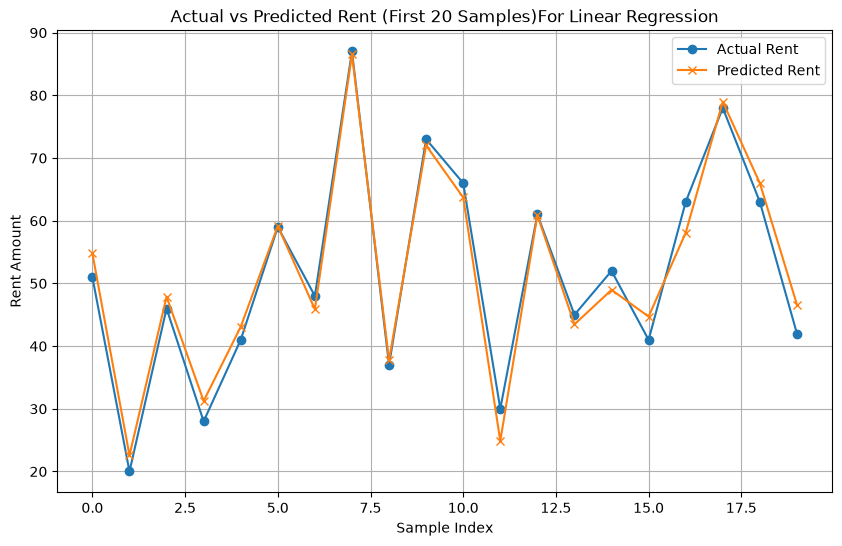

  7%|▋         | 1/15 [00:00<00:04,  3.38it/s]

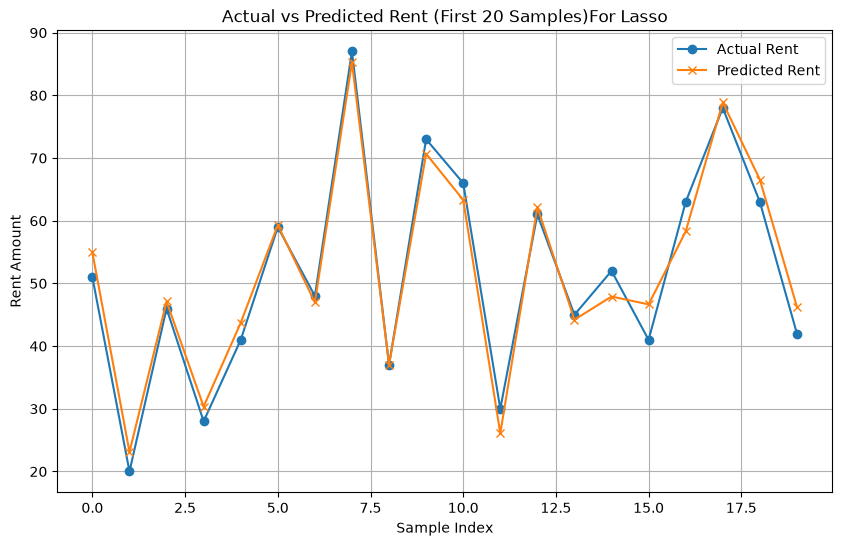

 13%|█▎        | 2/15 [00:00<00:03,  3.71it/s]

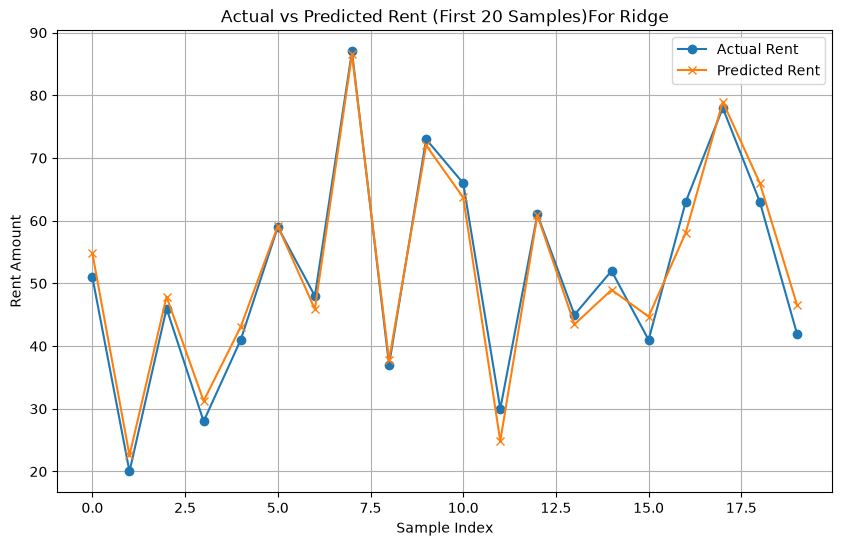

 20%|██        | 3/15 [00:00<00:03,  3.01it/s]

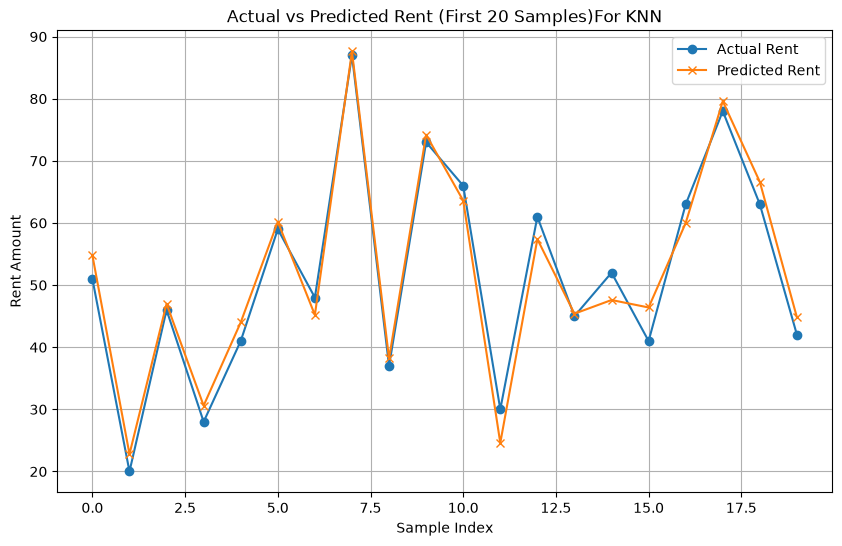

 27%|██▋       | 4/15 [00:01<00:04,  2.71it/s]

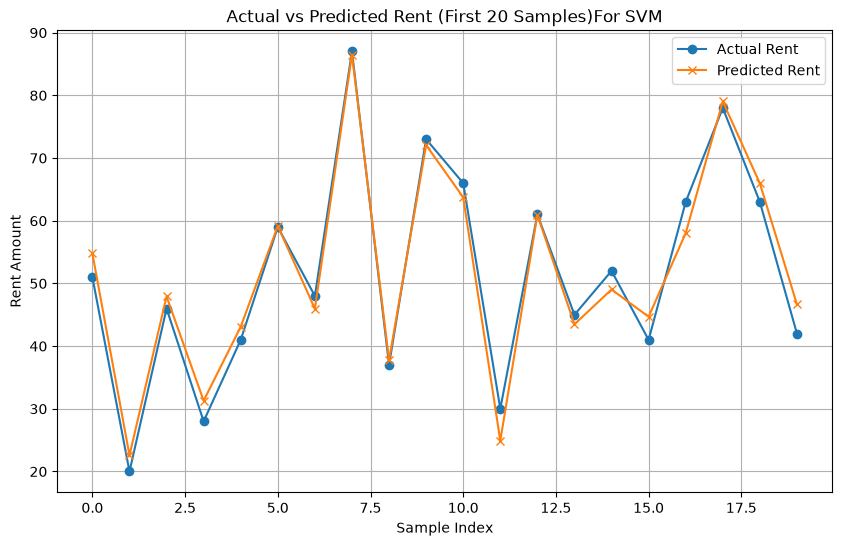

 33%|███▎      | 5/15 [15:06<54:28, 326.81s/it]

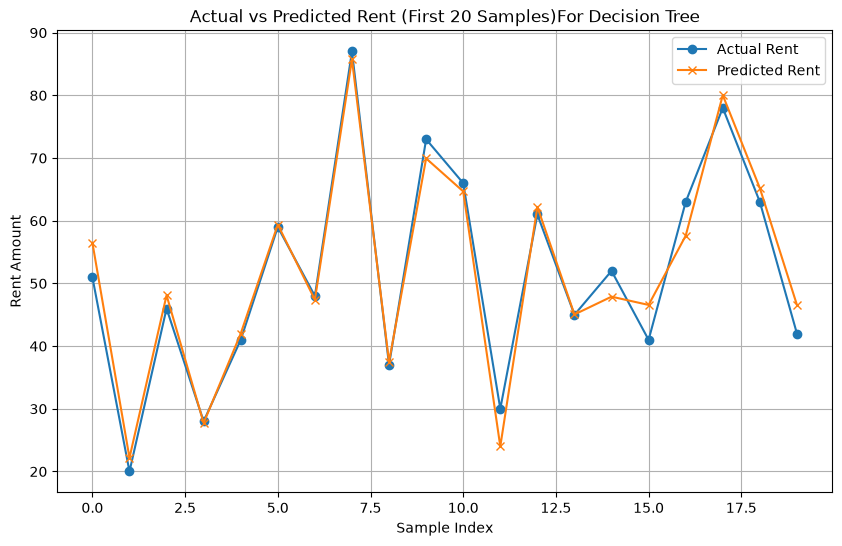

 40%|████      | 6/15 [15:07<32:21, 215.75s/it]

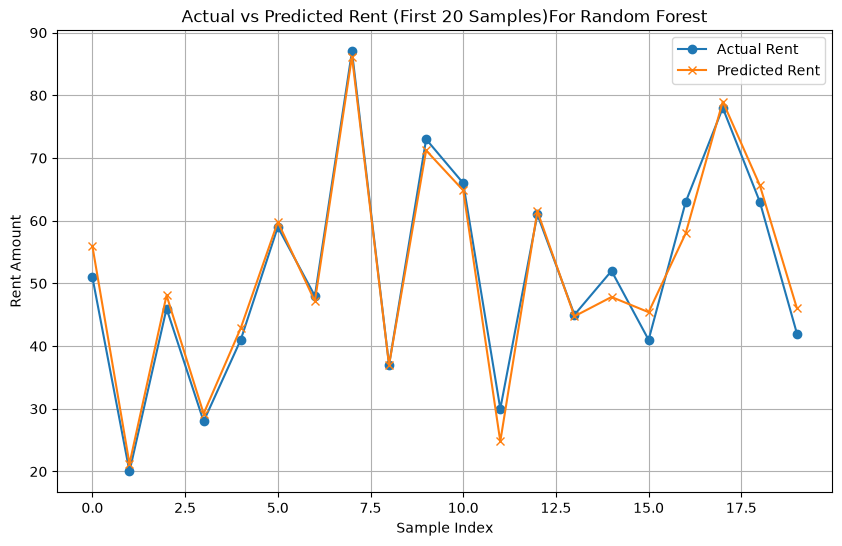

 47%|████▋     | 7/15 [15:07<19:23, 145.43s/it]

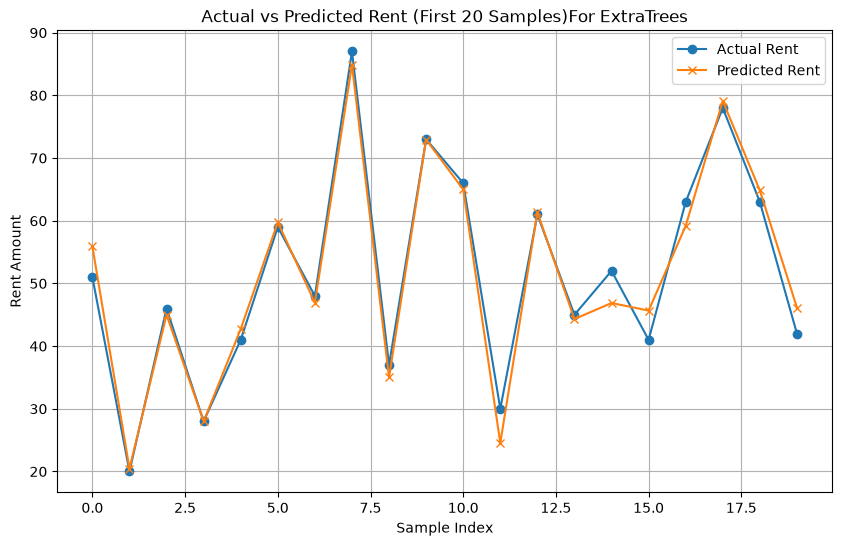

 53%|█████▎    | 8/15 [15:09<11:37, 99.61s/it] 

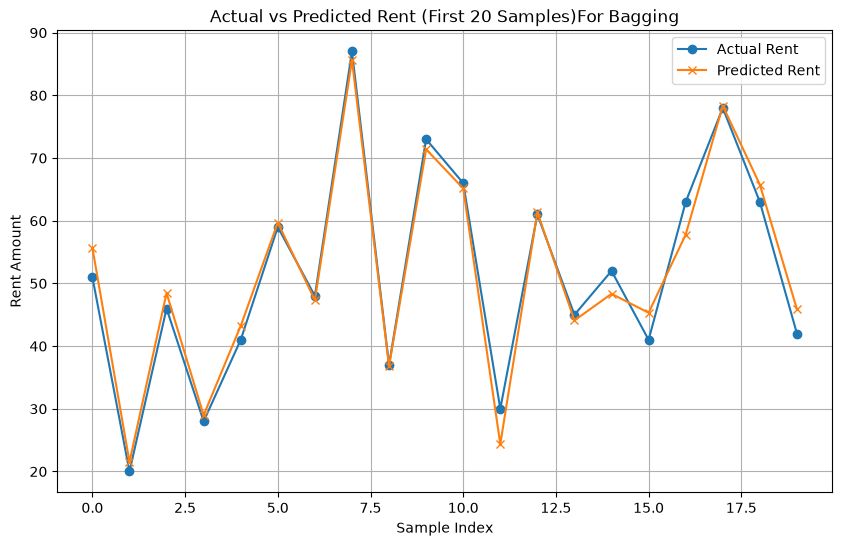

 60%|██████    | 9/15 [15:10<06:52, 68.71s/it]

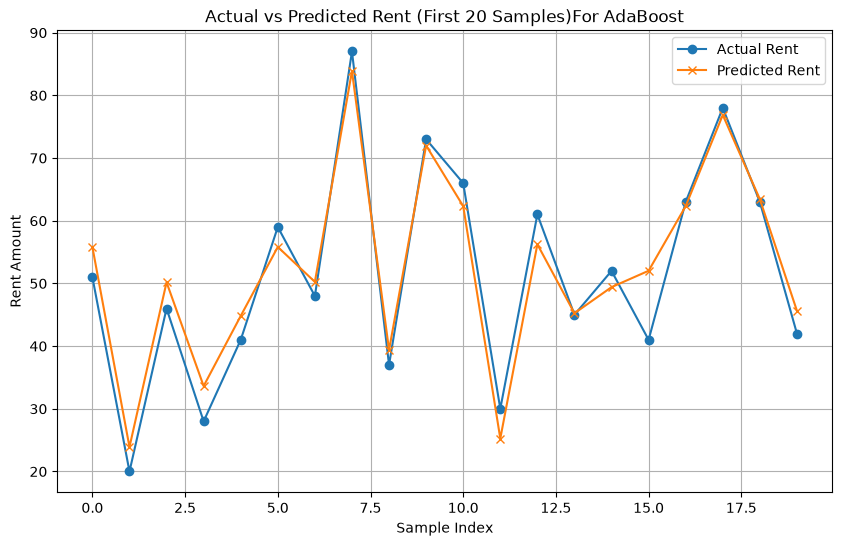

 67%|██████▋   | 10/15 [15:10<03:57, 47.59s/it]

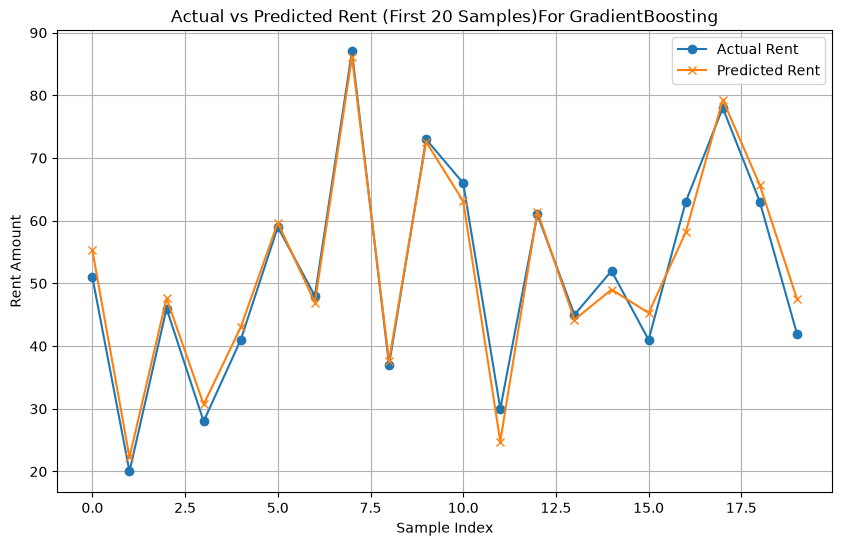

 73%|███████▎  | 11/15 [15:11<02:12, 33.23s/it]

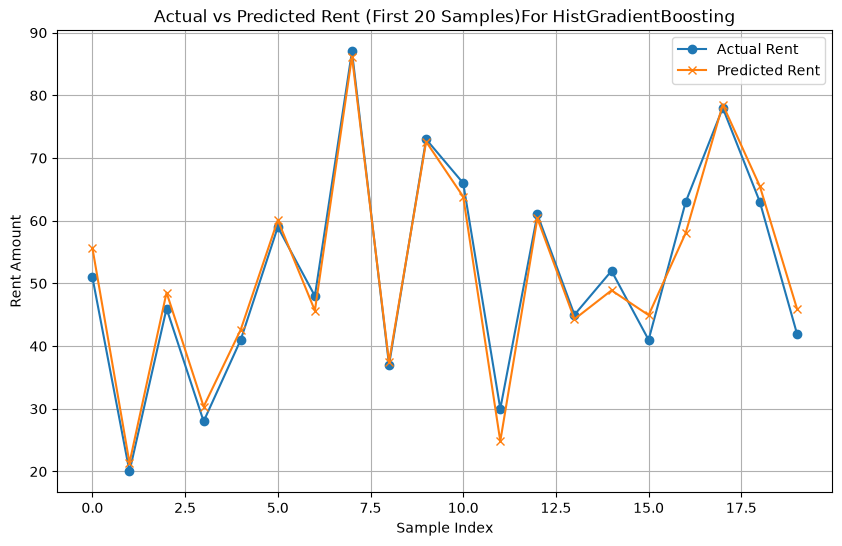

 80%|████████  | 12/15 [15:15<01:13, 24.42s/it]

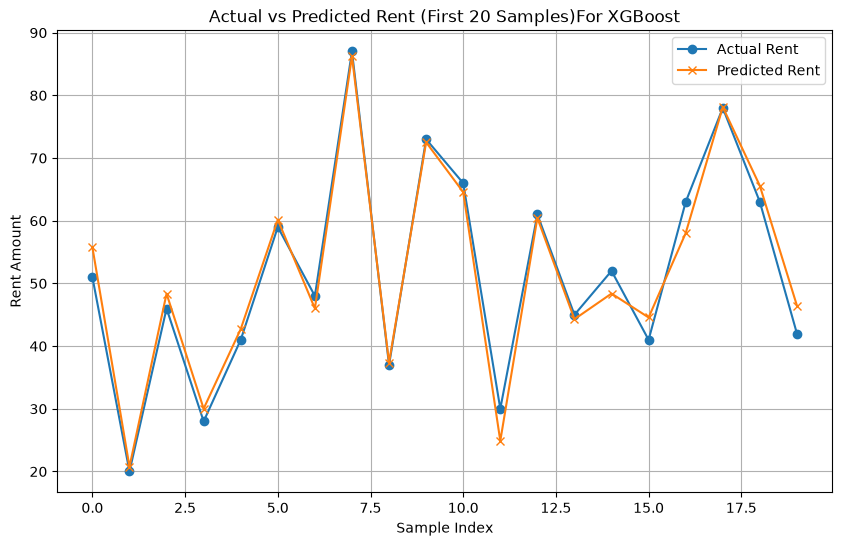

 87%|████████▋ | 13/15 [15:15<00:34, 17.12s/it]

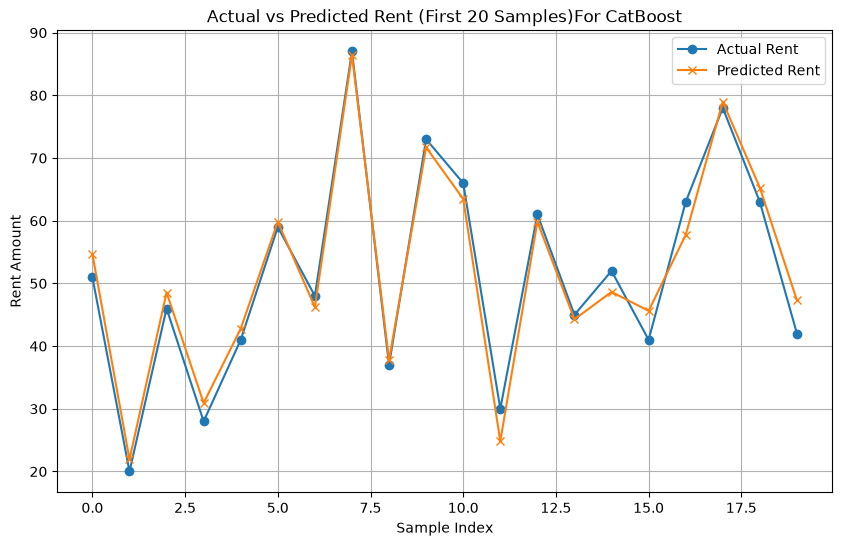

 93%|█████████▎| 14/15 [15:16<00:12, 12.11s/it]

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000095 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 90
[LightGBM] [Info] Number of data points in the train set: 8000, number of used features: 5
[LightGBM] [Info] Start training from score 55.311500


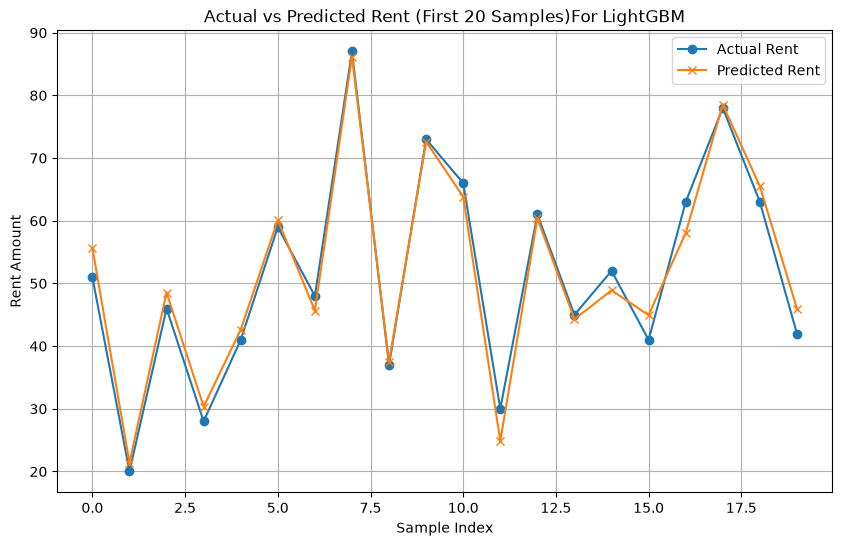

100%|██████████| 15/15 [15:16<00:00, 61.10s/it]


In [23]:
errors={}
for model_name , model in tqdm(models.items()):
    model.fit(X_train,y_train)
    MAE_Train, MSE_Train, RMSE_Train, R_Train = regression_metrics(model, X_train, y_train)
    MAE_Test, MSE_Test, RMSE_Test, R_Test = regression_metrics(model, X_test, y_test)
    
    errors[model_name] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R_Train,
        "R2 Test":R_Test
    }

    #Plotting Actual vs Predicted for first 20 test samples
    y_test_plot = y_test.values[:20]
    y_pred_plot = model.predict(X_test[:20])

    plt.figure(figsize=(10,6))
    plt.plot(range(20), y_test_plot, label='Actual Rent', marker='o')
    plt.plot(range(20), y_pred_plot, label='Predicted Rent', marker='x')
    plt.xlabel('Sample Index')
    plt.ylabel('Rent Amount')
    plt.title('Actual vs Predicted Rent (First 20 Samples)For '+ model_name)
    plt.legend()
    plt.grid()
    plt.show()

In [24]:
# Create individual regressors
clf1 = LinearRegression()
clf2 = RandomForestRegressor(n_estimators=50, random_state=1)
clf3 = DecisionTreeRegressor(random_state=1)

# Voting Regressors (only averaging is supported)
model1 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
])

model2 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
])

# Weighted averaging
model3 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
], weights=[2, 1, 2])

# Fit models
model1.fit(X_train, y_train)
model2.fit(X_train, y_train)
model3.fit(X_train, y_train)


# Model 1
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model1, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model1, X_test, y_test)

errors["Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

# Model 2
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model2, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model2, X_test, y_test)
errors["Simple Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

# Model 3
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model3, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model3, X_test, y_test)
errors["Weighted Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }


In [25]:
# -----------------------------
# Base models for stacking
# -----------------------------
regressors = [
    ('rf', RandomForestRegressor(n_estimators=50, random_state=42)),
    ('gb', GradientBoostingRegressor(n_estimators=50, learning_rate=0.1, random_state=42)),
    ('cat', CatBoostRegressor(iterations=50, learning_rate=0.1, verbose=0)),
    ('lgb', LGBMRegressor(n_estimators=50, learning_rate=0.1, random_state=42))
]

# -----------------------------
# Meta-model
# -----------------------------
meta_regressor = XGBRegressor()

# -----------------------------
# Stacking Models
# -----------------------------
stacking_regressor = StackingRegressor(
    estimators=regressors,
    final_estimator=meta_regressor,
    cv=5,
    passthrough=True,
    n_jobs=-1
)


stacking_regressor.fit(X_train, y_train)
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(stacking_regressor, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(stacking_regressor, X_test, y_test)
errors["Stacking"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

In [26]:
errors_df = pd.DataFrame(errors).T.sort_values(by="R2 Test",ascending=False)

In [27]:
errors_df

,MAE Train,MAE Test,MSE Train,MSE Test,RMSE Train,RMSE Test,R2 Train,R2 Test
Linear Regression,1.643061,1.638336,4.291231,4.224134,2.071529,2.055270,0.988360,0.988601
Ridge,1.643062,1.638339,4.291231,4.224149,2.071529,2.055274,0.988360,0.988601
SVM,1.642912,1.638993,4.292394,4.227161,2.071809,2.056006,0.988357,0.988593
HistGradientBoosting,1.540554,1.695681,3.764882,4.453931,1.940330,2.110434,0.989788,0.987981
LightGBM,1.540554,1.695718,3.764882,4.453982,1.940330,2.110446,0.989788,0.987981
XGBoost,1.468049,1.687972,3.453246,4.465673,1.858291,2.113214,0.990633,0.987950
CatBoost,1.633194,1.693362,4.254217,4.497470,2.062575,2.120724,0.988461,0.987864
GradientBoosting,1.642792,1.686291,4.271690,4.502077,2.066807,2.121810,0.988413,0.987851
Bagging,1.327289,1.762879,2.784430,4.861655,1.668661,2.204916,0.992447,0.986881
Random Forest,1.330858,1.761731,2.793255,4.913521,1.671303,2.216646,0.992423,0.986741


<Axes: >

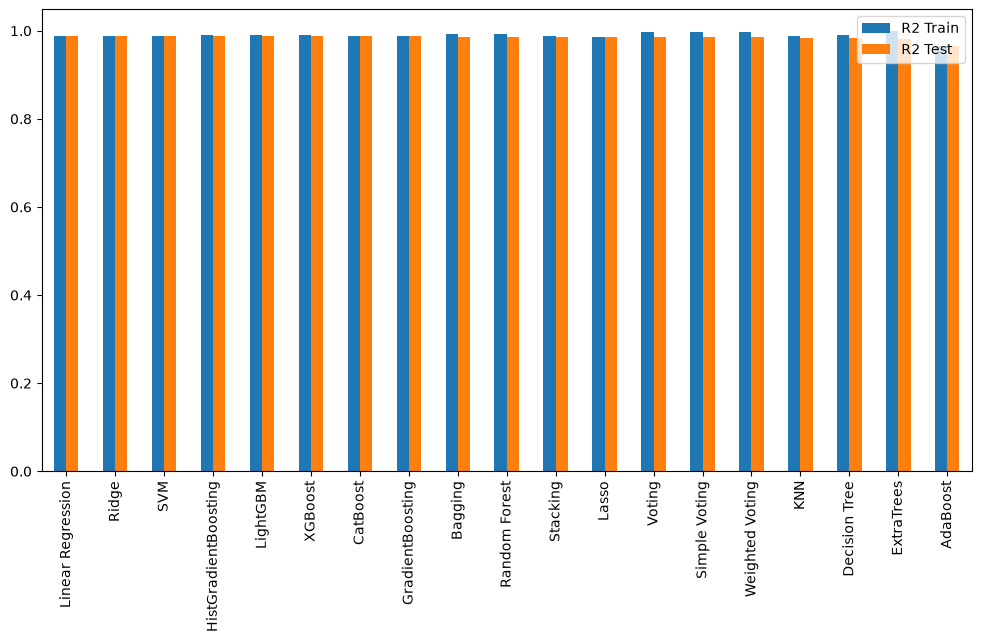

In [28]:
errors_df[["R2 Train", "R2 Test"]].plot.bar(figsize=(12,6))

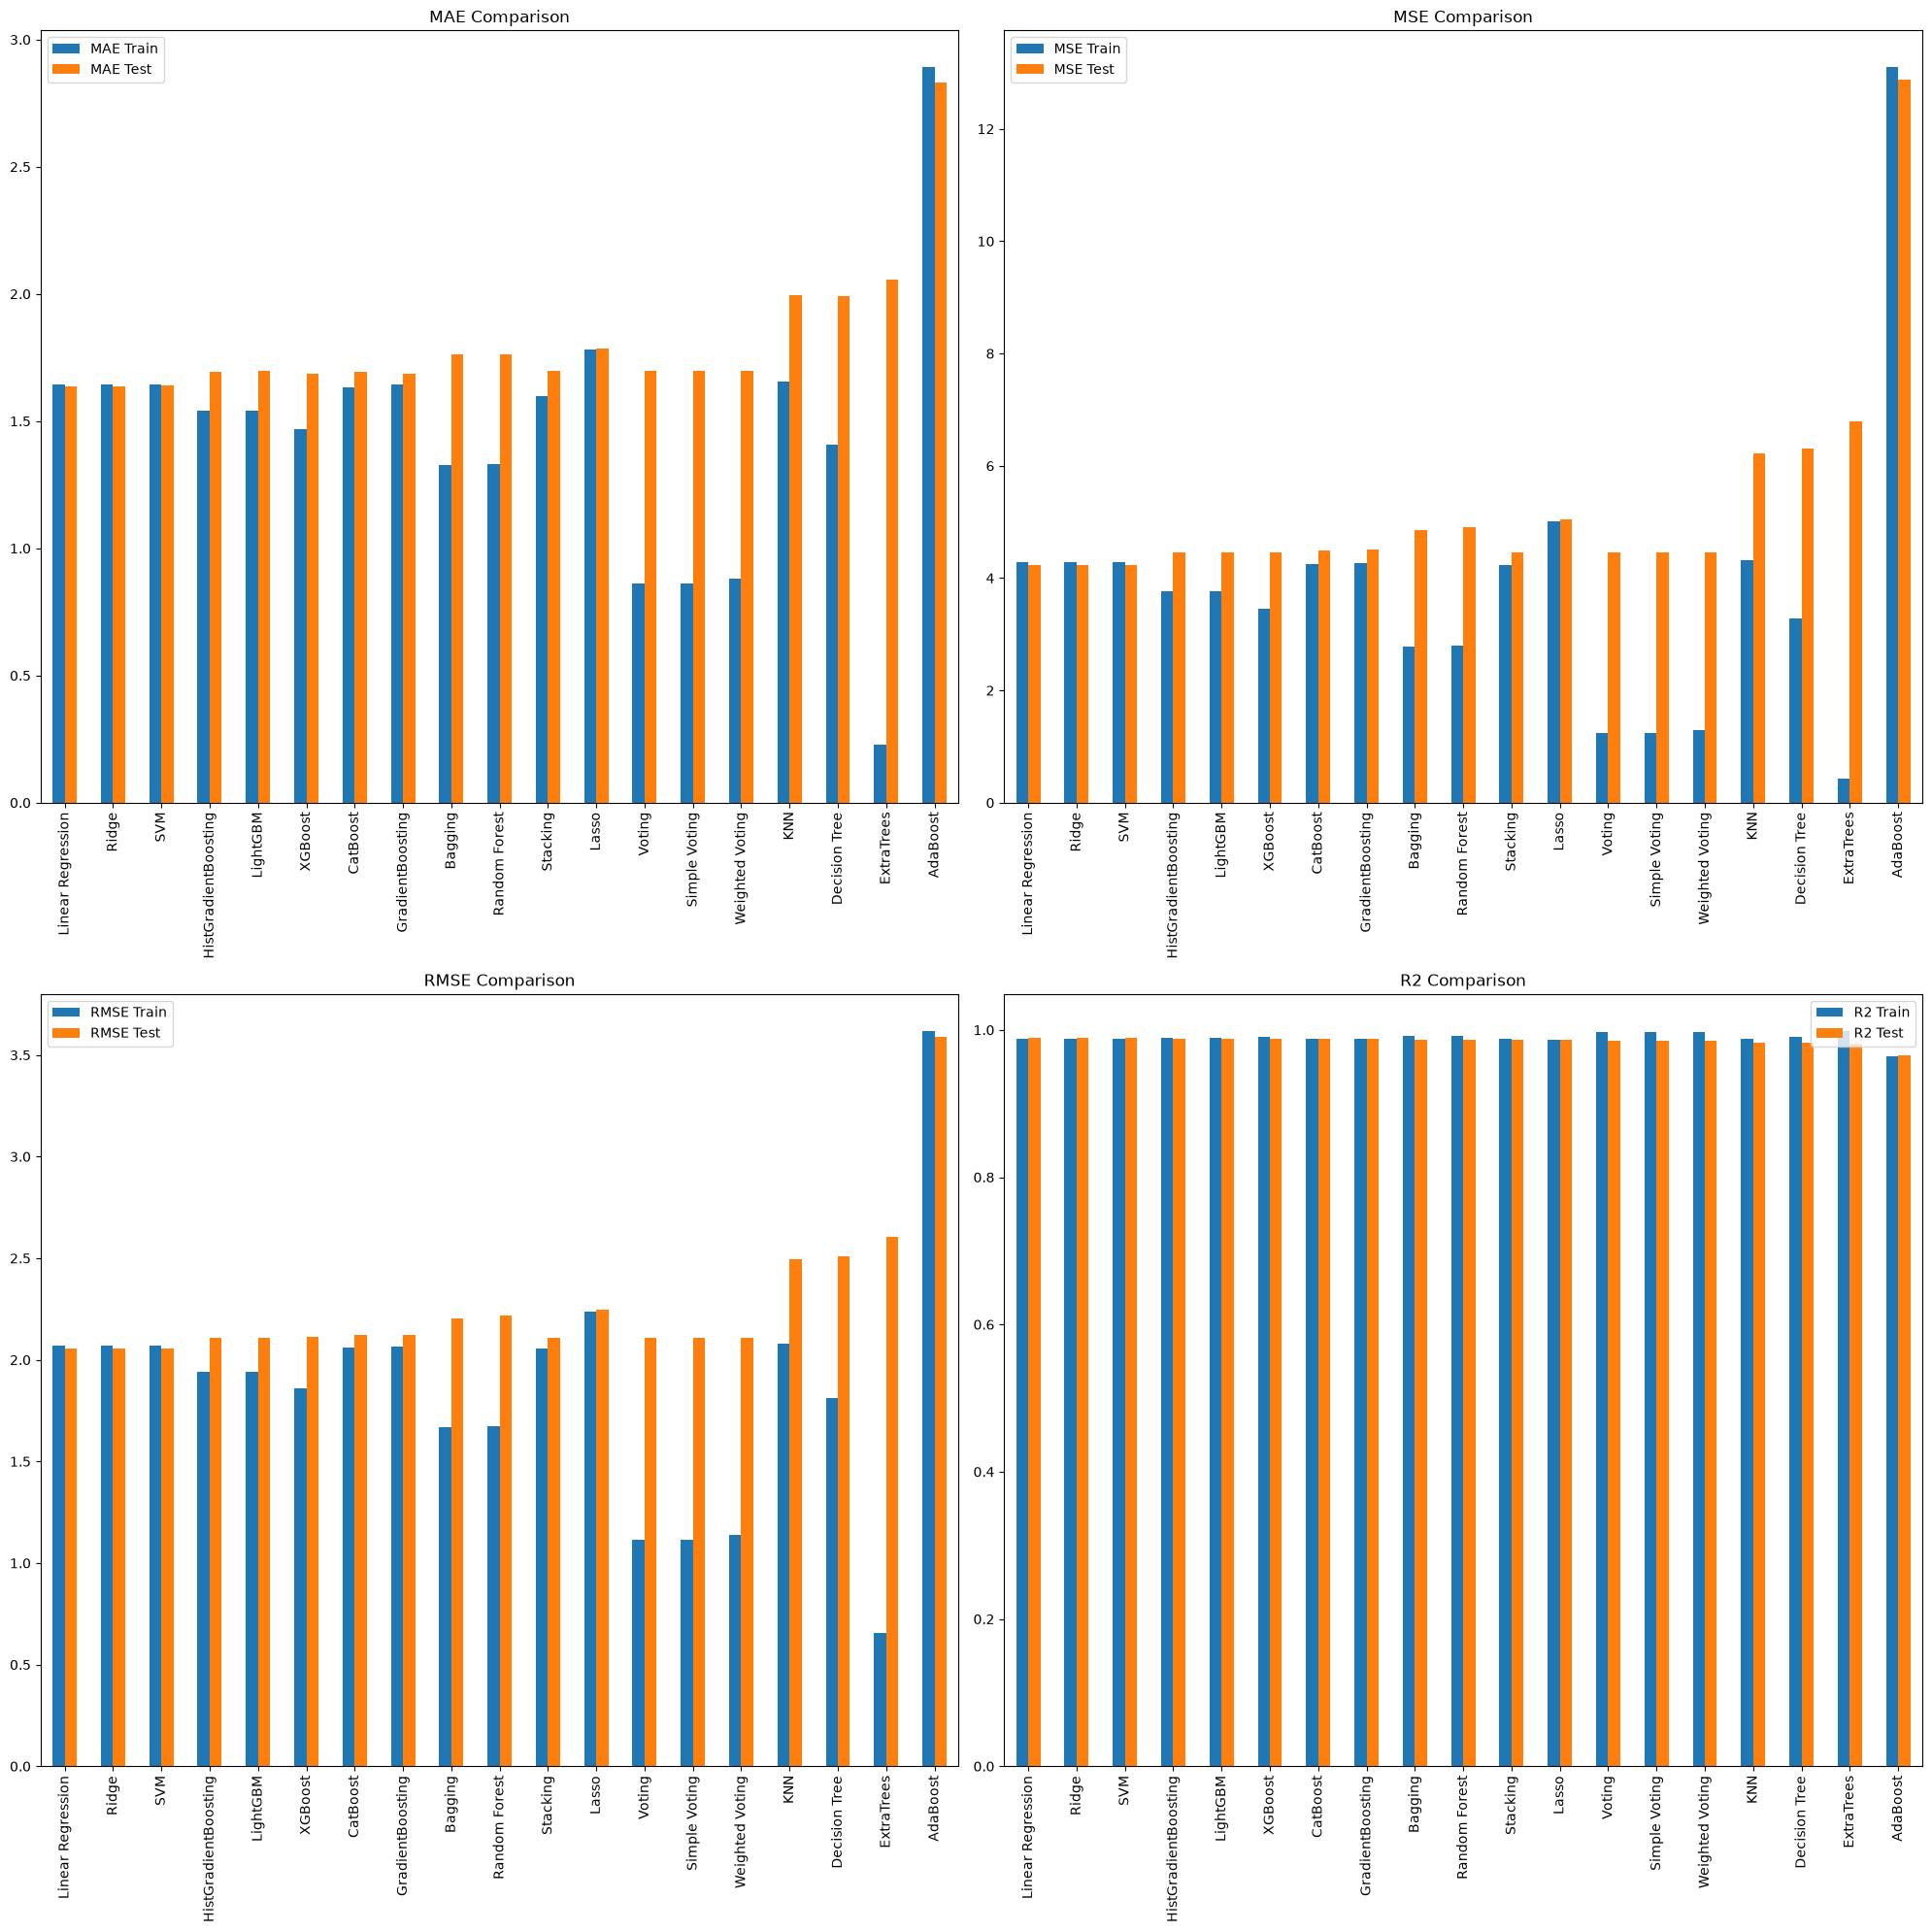

In [29]:
cols = [
    ['MAE Train', 'MAE Test'],
    ['MSE Train', 'MSE Test'],
    ['RMSE Train', 'RMSE Test'],
    ['R2 Train', 'R2 Test']
]

plt.figure(figsize=(20,20))

for i, col in enumerate(cols):
    ax = plt.subplot(2, 2, i+1)   
    errors_df[col].plot.bar(ax=ax)   
    ax.set_title(col[0].split(" ")[0] + ' Comparison')

plt.tight_layout()
plt.show()

In [30]:
from sklearn.decomposition import PCA

In [34]:

pc = PCA(n_components=5, random_state=42)
X_train_PCA = pc.fit_transform(X_train)
X_test_PCA = pc.transform(X_test)

In [35]:
X_train_PCA.shape

(8000, 5)

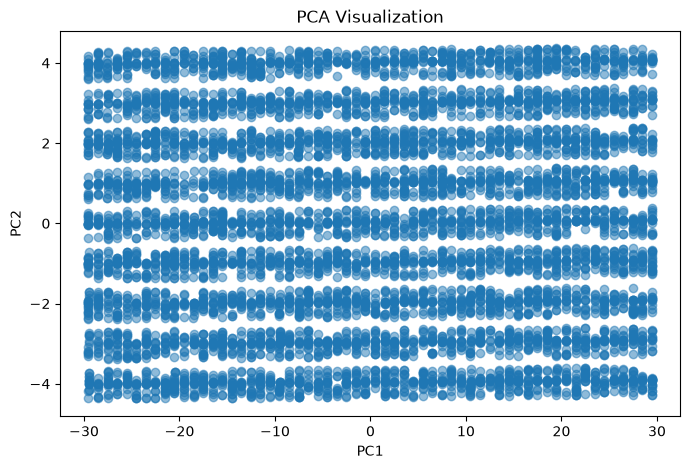

In [36]:
plt.figure(figsize=(8, 5))

plt.scatter(X_train_PCA[:, 0], X_train_PCA[:, 1], alpha=0.5)

plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('PCA Visualization')

plt.show()

In [37]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

numeric_features = [
    'Hours Studied',
    'Previous Scores',
    'Sleep Hours',
    'Sample Question Papers Practiced'
]

categorical_features = [
    'Extracurricular Activities'
]

numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(drop='if_binary', handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', numeric_pipeline, numeric_features),
    ('cat', categorical_pipeline, categorical_features)
])

In [38]:
X = df.drop('Performance Index', axis=1)
y = df['Performance Index']

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

In [39]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV

pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(random_state=42))
])

param_grid = {
    'model__n_estimators': [100, 200, 300],
    'model__max_depth': [None, 5, 10, 15],
    'model__min_samples_split': [2, 5, 10]
}

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__max_depth': [None, 5, ...], 'model__min_samples_split': [2, 5, ...], 'model__n_estimators': [100, 200, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verb

In [40]:
print("Best Parameters:", grid_search.best_params_)
print("Best Score:", grid_search.best_score_)

y_pred = grid_search.predict(X_test)

Best Parameters: {'model__max_depth': 10, 'model__min_samples_split': 10, 'model__n_estimators': 300}
Best Score: 0.9862870399586111


In [41]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

print("R2:", r2_score(y_test, y_pred))
print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))

R2: 0.987080133526211
MAE: 1.7430684596942219
MSE: 4.787910215893587


In [42]:
import joblib

joblib.dump(grid_search.best_estimator_, 'model.pkl')

['model.pkl']